Swapped label on 1 records
Swapped label on 2 records
Swapped label on 3 records
Swapped label on 4 records
Swapped label on 5 records
Swapped label on 6 records
Swapped label on 7 records
Swapped label on 8 records
Swapped label on 9 records
Swapped label on 10 records
Swapped label on 11 records
Swapped label on 12 records
Swapped label on 13 records
Swapped label on 14 records
Swapped label on 15 records
Swapped label on 16 records
Swapped label on 17 records
Swapped label on 18 records
Swapped label on 19 records
Swapped label on 20 records
Swapped label on 21 records
Swapped label on 22 records
Swapped label on 23 records
Swapped label on 24 records
Swapped label on 25 records
Swapped label on 26 records
Swapped label on 27 records
Swapped label on 28 records
Swapped label on 29 records
Swapped label on 30 records
Swapped label on 31 records
Swapped label on 32 records
Swapped label on 33 records
Swapped label on 34 records
Swapped label on 35 records
Swapped label on 36 records
S

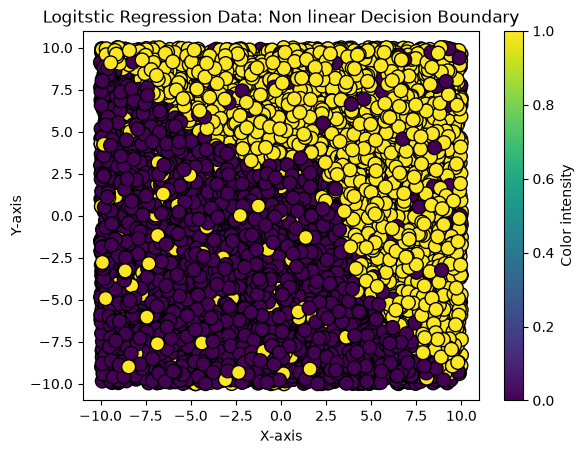

In [1]:
# -*- coding: utf-8 -*-
"""
@author: parra
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

theta_vector = np.array([-25,0,0,1,1,1,1,1])
N = 60_000
np.random.seed(10)
x1_inputs = np.random.uniform(-10, 10, size=N)
np.random.seed(100)
x2_inputs = np.random.uniform(-10, 10, size=N)

row_list = []
labels = []

for x1,x2 in zip(x1_inputs,x2_inputs):
    x_i_vector = np.array([1,x1,x2,x1**2,x2**2,x1**3,x2**3,x1*x2])
    #x_i_vector = np.array([1,x1,x2,x1**2,x2**2,x1**3,x2**3,x1**4])
    row_list.append(x_i_vector)
    
    hypothesis_prediction = np.dot(theta_vector, x_i_vector)
    if hypothesis_prediction >= 25:
        labels.append(1)
    else:
        labels.append(0)

## add some noise to labels so that the two classes are not perfectly seperable

ctr = 1
noisy_labels = []
for x in labels:
    if np.random.random()>.92:
        noisy_labels.append(1 - x)
        print(f"Swapped label on {ctr} records")
        ctr += 1
    else:
        noisy_labels.append(x)



design_matrix = np.array(row_list)
col_names = ['intercept','x1','x2','x1_squared','x2_squared','x1_cubed','x2_cubed','x1_times_x2']
data = pd.DataFrame(row_list,columns = col_names)
data['label'] = noisy_labels
np.random.seed(123)
test_portion = .10
test_ids = np.random.choice(np.arange(0, data.shape[0]), size=int(test_portion*data.shape[0]), replace=False)
test_data = data[data.index.isin(test_ids)]
training_data = data[~data.index.isin(test_ids)]

training_data = training_data.reset_index()
test_data = test_data.reset_index()

test_data['type'] = 'test'
training_data['type'] = 'train'

full_data = pd.concat([test_data,training_data])

cols_to_keeps = ['x1','x2','label']

# draw a sample to use for actual model selection and evaluation

np.random.seed(123)
sample_size = min(300, training_data.shape[0])
sample_ids = np.random.choice(np.arange(0, training_data.shape[0]), size=sample_size, replace=False)
sample_data = training_data[training_data.index.isin(sample_ids)]
sample_data[cols_to_keeps].to_csv('SAMPLE_DATA.csv', index=False)


# Create the scatter plot
plot_size = 10_000
plt.scatter(x1_inputs[0:plot_size],
            x2_inputs[0:plot_size],
            c=noisy_labels[0:plot_size],
            cmap='viridis',
            s=100,
            edgecolor='k')

# Add a color bar
plt.colorbar(label='Color intensity')

# Add labels and title
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Logitstic Regression Data: Non linear Decision Boundary')

# Show the plot
plt.show()


In [2]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# which features each model gets
raw   = ['x1', 'x2']                                              # raw features only
cubic = ['x1', 'x2', 'x1_squared', 'x2_squared',
         'x1_cubed', 'x2_cubed', 'x1_times_x2']                   # extra features made by the script

y_train = sample_data['label'].values    # 300 training points
y_test  = test_data['label'].values      # 6,000 test points

models = {
    "Logistic (linear)": (LogisticRegression(), raw),             #straight line
    "Logistic (cubic)":  (LogisticRegression(max_iter=5000), cubic),  # curved boundary
    "KNN k=1":           (KNeighborsClassifier(n_neighbors=1), raw),
    "KNN k=15":          (KNeighborsClassifier(n_neighbors=15), raw),
    "KNN k=50":          (KNeighborsClassifier(n_neighbors=50), raw),
    "KNN k=300":         (KNeighborsClassifier(n_neighbors=300), raw),  # k = n
}

results = []
for name, (m, cols) in models.items():
    m.fit(sample_data[cols].values, y_train)                                   # learn
    train_error = 1 - accuracy_score(y_train, m.predict(sample_data[cols].values))
    test_error  = 1 - accuracy_score(y_test,  m.predict(test_data[cols].values))
    results.append({"Model": name,
                    "Training error rate (%)": round(train_error * 100, 1),
                    "Test error rate (%)":     round(test_error * 100, 1)})

results = pd.DataFrame(results).set_index("Model")
results          # labeled table, lower = better

,Training error rate (%),Test error rate (%)
Model,,
Logistic (linear),13.3,13.5
Logistic (cubic),10.7,12.3
KNN k=1,0.0,16.9
KNN k=15,9.0,12.6
KNN k=50,14.3,13.8
KNN k=300,46.7,43.8


Which model would I choose?

I would not choose KNN k=1, even though its training error is 0%. About 8% of the labels are flipped on purpose (irreducible error), so a 0% training error means the model memorized the noise. Its test error (16.9%) is actually the worst of the realistic model, a clear case of overfitting.

Looking at the test error, the two best models are Logistic (cubic) at 12.3% and KNN k=15 at 12.6%. The difference is very small (0.3 points), so in practice they perform about the same. The choice depends on what I need the model for:

- Logistic (cubic) if I want to interpret the model (inference): it gives coefficients, it's fast, and it works because I gave it the right shape. But in real life I usually don't know the true shape in advance.
- KNN k=15 if I only care about prediction and don't know the shape of the boundary: it finds the curve by itself from the data, without assuming any form.

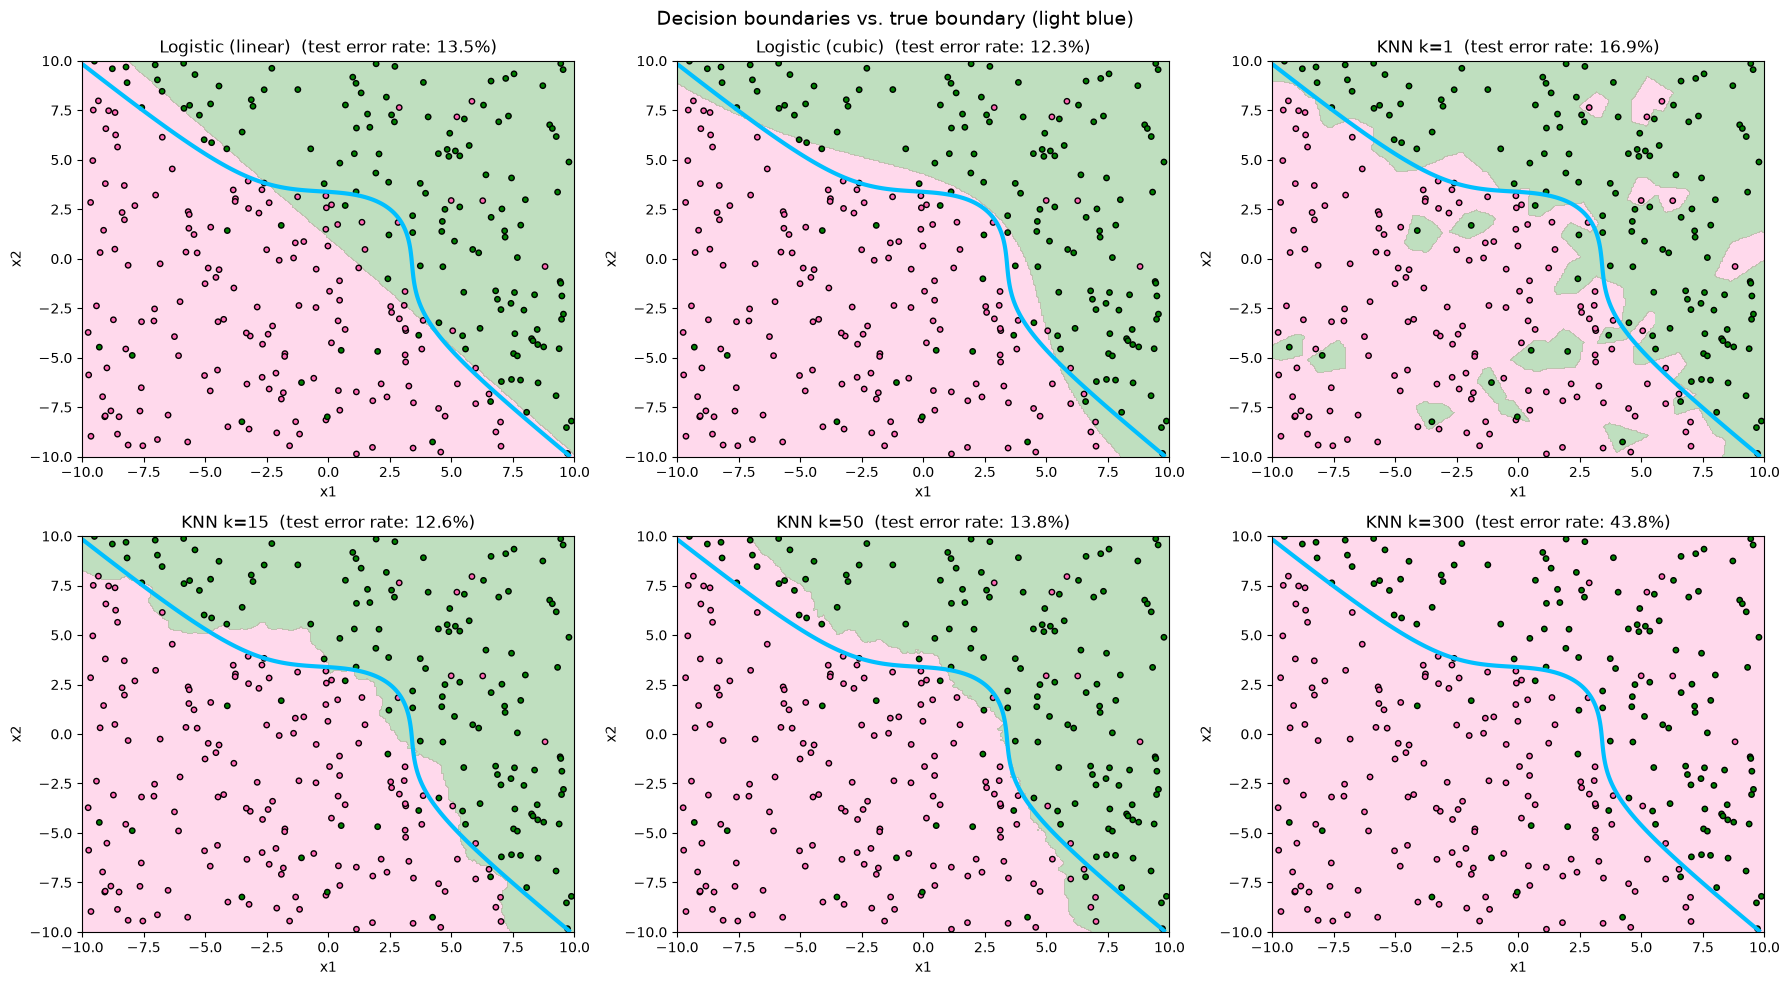

In [3]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["hotpink", "green"])          # 0 = pink, 1 = green

# grid covering the whole square, with all the features the models might need
xx, yy = np.meshgrid(np.linspace(-10, 10, 300), np.linspace(-10, 10, 300))
x1g, x2g = xx.ravel(), yy.ravel()
grid = pd.DataFrame({'x1': x1g, 'x2': x2g,
                     'x1_squared': x1g**2, 'x2_squared': x2g**2,
                     'x1_cubed': x1g**3,   'x2_cubed': x2g**3,
                     'x1_times_x2': x1g * x2g})

true_score = -25 + xx**2 + yy**2 + xx**3 + yy**3 + xx*yy      # true rule from the script
X_train_raw = sample_data[raw].values

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()
for ax, (name, (m, cols)) in zip(axes, models.items()):
    zz = m.predict(grid[cols].values).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], cmap=cmap, alpha=0.25)   # model's decision areas
    ax.scatter(X_train_raw[:, 0], X_train_raw[:, 1], c=y_train, cmap=cmap,
               vmin=0, vmax=1, s=15, edgecolor="k")                          # 300 training points
    ax.contour(xx, yy, true_score, levels=[25],
               colors="deepskyblue", linewidths=3)                           # true boundary (light blue)
    ax.set_title(f"{name}  (test error rate: {results.loc[name, 'Test error rate (%)']}%)")
    ax.set_xlabel("x1"); ax.set_ylabel("x2")

for ax in axes[len(models):]:      # hide the empty spot
    ax.axis("off")

fig.suptitle("Decision boundaries vs. true boundary (light blue)", fontsize=14)
plt.tight_layout()
plt.savefig("decision_boundaries_cubic.png", dpi=150)   # picture saved for your post
plt.show()